| TID | Definition |
|:---:|---|
| 0 | Land |
| **Direct measurements** | |
| 10 | Singlebeam - depth value collected by a single beam echo-sounder |
| 11 | Multibeam - depth value collected by a multibeam echo-sounder |
| 12 | Seismic - depth value collected by seismic methods |
| 13 | Isolated sounding - depth value that is not part of a regular survey or trackline |
| 14 | ENC sounding - depth value extracted from an Electronic Navigation Chart (ENC) |
| 15 | Lidar - depth derived from a bathymetric lidar sensor |
| 16 | Depth measured by optical light sensor |
| 17 | Combination of direct measurement methods |
| **Indirect measurements** | |
| 40 | Predicted based on satellite-derived gravity data - depth value is an interpolated value guided by satellite-derived gravity data |
| 41 | Interpolated based on a computer algorithm - depth value is an interpolated value based on a computer algorithm (e.g. Generic Mapping Tools) |
| 42 | Digital bathymetric contours from charts - depth value taken from a bathymetric contour data set |
| 43 | Digital bathymetric contours from ENCs - depth value taken from bathymetric contours from an Electronic Navigation Chart (ENC) |
| 44 | Depth value at this location is based on bathymetric depths from multiple sources including measured and derived data and included within a gridded data set where interpolation between sounding points is guided by satellite-derived gravity data |
| 45 | Predicted based on helicopter/flight-derived gravity data |
| 46 | Depth estimated by calculating the draft of a grounded iceberg using satellite-derived freeboard measurement |
| 47 | Depth derived from grounded Argo float data |
| 48 | Depth measured by animal-borne data loggers |
| **Unknown** | |
| 70 | Pre-generated grid - depth value is taken from a pre-generated grid that is based on mixed source data types, e.g. single beam, multibeam, interpolation etc. |
| 71 | Unknown source - depth value from an unknown source |
| 72 | Steering points - depth value used to constrain the grid in areas of poor data coverage |

In [1]:
# Instalamos rasterio y herramientas geoespaciales avanzadas
!pip install -q netCDF4 xarray matplotlib scipy numpy rasterio

import os
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from scipy.interpolate import NearestNDInterpolator
import rasterio
from rasterio.transform import from_bounds

In [2]:
# --- CONFIGURACIÓN DE RUTAS
archivo_gebco = '/content/gebco_2026_n-53.675_s-55.082_w-62.003_e-55.655.nc'        # NetCDF
archivo_tid = '/content/gebco_2026_tid_n-53.675_s-55.082_w-62.003_e-55.655.nc'      # (TID) NetCDF

# Verificar si los archivos existen; si no, avisar al usuario
if not os.path.exists(archivo_gebco) or not os.path.exists(archivo_tid):
    print("⚠️ Archivos no encontrados en el entorno actual.")
    print("Por favor, sube tus archivos .nc de GEBCO y TID, o ajusta las rutas en las variables.")
else:
    # Cargar datasets usando xarray
    ds_elev = xr.open_dataset(archivo_gebco)
    ds_tid = xr.open_dataset(archivo_tid)

    # Nota: Los nombres de las variables comunes en GEBCO suelen ser 'elevation' (o 'z') y 'tid'
    print("Variables en el NetCDF de elevación:", list(ds_elev.data_vars))
    print("Variables en el NetCDF de TID:", list(ds_tid.data_vars))

Variables en el NetCDF de elevación: ['crs', 'elevation']
Variables en el NetCDF de TID: ['crs', 'tid']


In [3]:
# (Asumiendo que los archivos se cargaron correctamente, adaptamos los nombres de variables estándar de GEBCO)
# Si tus variables tienen nombres distintos (ej. 'z'), cámbialos aquí:
var_elev = 'elevation' if 'elevation' in ds_elev else 'z'
var_tid = 'tid' if 'tid' in ds_tid else list(ds_tid.data_vars)[0]

lons = ds_elev['lon'].values
lats = ds_elev['lat'].values
elevation = ds_elev[var_elev].values
tid_grid = ds_tid[var_tid].values

# Crear malla 2D si vienen en vectores 1D o asegurarla
if len(elevation.shape) == 1:
    lon2d, lat2d = np.meshgrid(lons, lats)
else:
    lon2d, lat2d = np.meshgrid(lons, lats)

# Filtrar celdas de alta confianza (ej. TID 1 o 10 para sondeos directos, ajusta según la tabla oficial de GEBCO)
# Consulta la documentación de GEBCO para los códigos TID específicos de tu versión.
mask_measured = (tid_grid == 1) | (tid_grid == 10)

print(f"Total de celdas en la zona: {elevation.size}")
print(f"Celdas con mediciones directas (TID 1 o 10): {mask_measured.sum()}")

Total de celdas en la zona: 515112
Celdas con mediciones directas (TID 1 o 10): 32397


In [4]:
# Extraer puntos válidos medidos
points_x = lon2d[mask_measured].flatten()
points_y = lat2d[mask_measured].flatten()
values_z = elevation[mask_measured].flatten()

# Ejecutar el interpolador Nearest Neighbor con SciPy
print("Calculando interpolación por vecinos más próximos...")
interpolator = NearestNDInterpolator(list(zip(points_x, points_y)), values_z)

grid_x, grid_y = lon2d.flatten(), lat2d.flatten()
interpolated_elevation = interpolator(grid_x, grid_y).reshape(lon2d.shape)
print("¡Interpolación completada!")

Calculando interpolación por vecinos más próximos...
¡Interpolación completada!


In [5]:
# Definir nombre del archivo GeoTIFF de salida
output_tif = '/content/gebco_interpolated_nn.tif'

# Obtener límites geográficos de la rejilla
xmin, xmax = lons.min(), lons.max()
ymin, ymax = lats.min(), lats.max()
height, width = interpolated_elevation.shape

# Calcular la transformación afín (georeferenciación)
# Nota: GEBCO suele almacenar las latitudes de norte a sur o sur a norte.
# Asegurarnos de que el origen y la resolución vertical sean correctos para Rasterio.
resolution_x = (xmax - xmin) / width
resolution_y = (ymax - ymin) / height

# Si las latitudes vienen ordenadas de norte a sur, ajustamos el transform
if lats[0] > lats[-1]:
    # Invertir el arreglo verticalmente para que Rasterio lo escriba de sur a norte correctamente
    interpolated_elevation = np.flipud(interpolated_elevation)
    transform = from_bounds(xmin, ymin, xmax, ymax, width, height)
else:
    transform = from_bounds(xmin, ymin, xmax, ymax, width, height)

# Escribir el archivo GeoTIFF
metadata = {
    'driver': 'GTiff',
    'height': height,
    'width': width,
    'count': 1,  # Una sola banda (batimetría/elevación)
    'dtype': str(interpolated_elevation.dtype),
    'crs': 'EPSG:4326',  # Sistema de Coordenadas WGS84 estándar de GEBCO
    'transform': transform,
    'nodata': np.nan     # Definir valor nulo si aplica
}

with rasterio.open(output_tif, 'w', **metadata) as dst:
    dst.write(interpolated_elevation, 1)

print(f"✅ Archivo GeoTIFF exportado exitosamente como: {output_tif}")

✅ Archivo GeoTIFF exportado exitosamente como: /content/gebco_interpolated_nn.tif


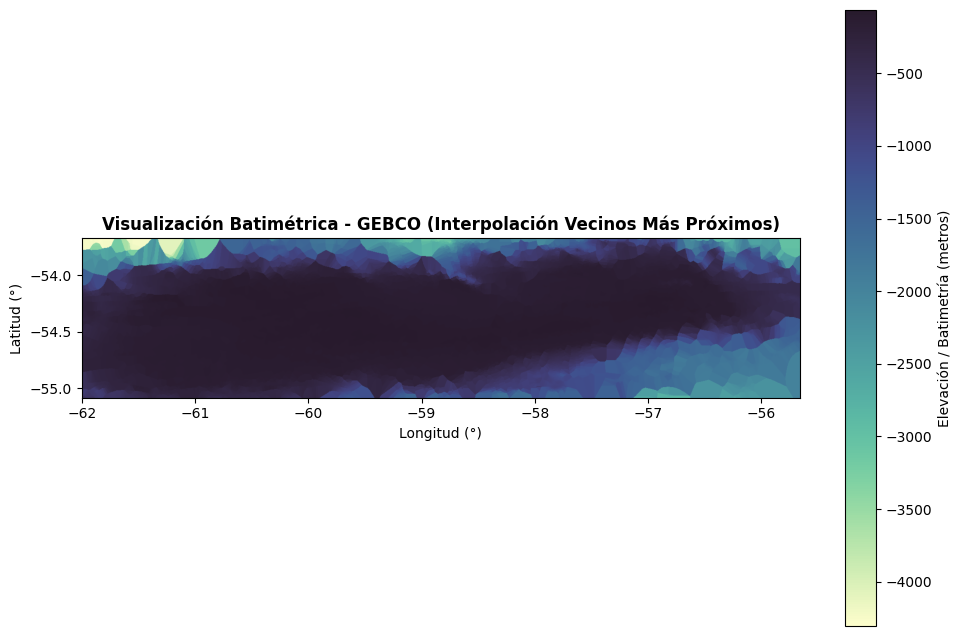

In [6]:
# Instalar cmocean si deseas paletas oceanográficas profesionales (opcional pero recomendado)
!pip install -q rasterio matplotlib numpy cmocean

import rasterio
from rasterio.plot import show
import matplotlib.pyplot as plt
import numpy as np
try:
    import cmocean.cm as cmo
    has_cmocean = True
except ImportError:
    has_cmocean = False

# Ruta de tu archivo GeoTIFF exportado previamente
archivo_tif = '/content/gebco_interpolated_nn.tif'

# Abrir el ráster con Rasterio
with rasterio.open(archivo_tif) as src:
    # Leer la primera banda
    raster_data = src.read(1)
    # Obtener los límites espaciales (bounding box) para los ejes del mapa
    bounds = src.bounds
    extent = [bounds.left, bounds.right, bounds.bottom, bounds.top]

    # Manejar valores nodata si existen (convertirlos a NaN para que matplotlib los ignore)
    nodata = src.nodata
    if nodata is not None:
        raster_data = np.where(raster_data == nodata, np.nan, raster_data)

# Crear la figura de visualización
fig, ax = plt.subplots(figsize=(10, 8))

# Seleccionar la paleta de colores (usamos cmocean 'deep' o 'blues' si no está instalado)
cmap_to_use = cmo.deep if has_cmocean else 'Blues_r'

# Graficar la batimetría interpolada
im = ax.imshow(
    raster_data,
    extent=extent,
    origin='upper', # Ajustar según cómo se guardó en el paso anterior
    cmap=cmap_to_use
)

# Añadir barra de colores y etiquetas
cbar = plt.colorbar(im, ax=ax, shrink=0.8, label='Elevación / Batimetría (metros)')
ax.set_title('Visualización Batimétrica - GEBCO (Interpolación Vecinos Más Próximos)', fontsize=12, fontweight='bold')
ax.set_xlabel('Longitud (°)', fontsize=10)
ax.set_ylabel('Latitud (°)', fontsize=10)

# Mostrar la gráfica
plt.tight_layout()
plt.show()

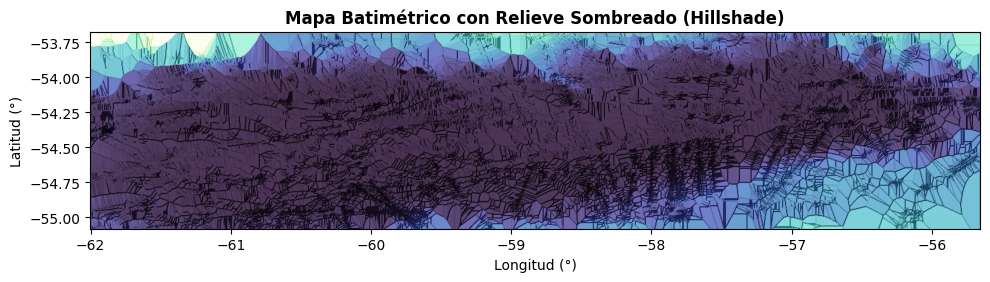

In [7]:
from matplotlib.colors import LightSource

# Configurar la fuente de luz para simular el sol (azimut y elevación del sol)
ls = LightSource(azdeg=315, altdeg=45)

# Crear una figura con sombreado integrado (mezcla la paleta batimétrica con el relieve de iluminación)
fig, ax = plt.subplots(figsize=(10, 8))

# Generar la imagen con hillshade sombreado
rgb = ls.shade(raster_data, cmap=cmap_to_use, vert_exag=100.0, blend_mode='soft')

ax.imshow(rgb, extent=extent, origin='upper')
ax.set_title('Mapa Batimétrico con Relieve Sombreado (Hillshade)', fontsize=12, fontweight='bold')
ax.set_xlabel('Longitud (°)')
ax.set_ylabel('Latitud (°)')

plt.tight_layout()
plt.show()

Variables disponibles en tu NetCDF: ['crs', 'tid']
Variable TID seleccionada: tid
Dimensiones de la matriz TID: (338, 1524)
Códigos TID encontrados en esta zona: [10. 11. 17. 41.]


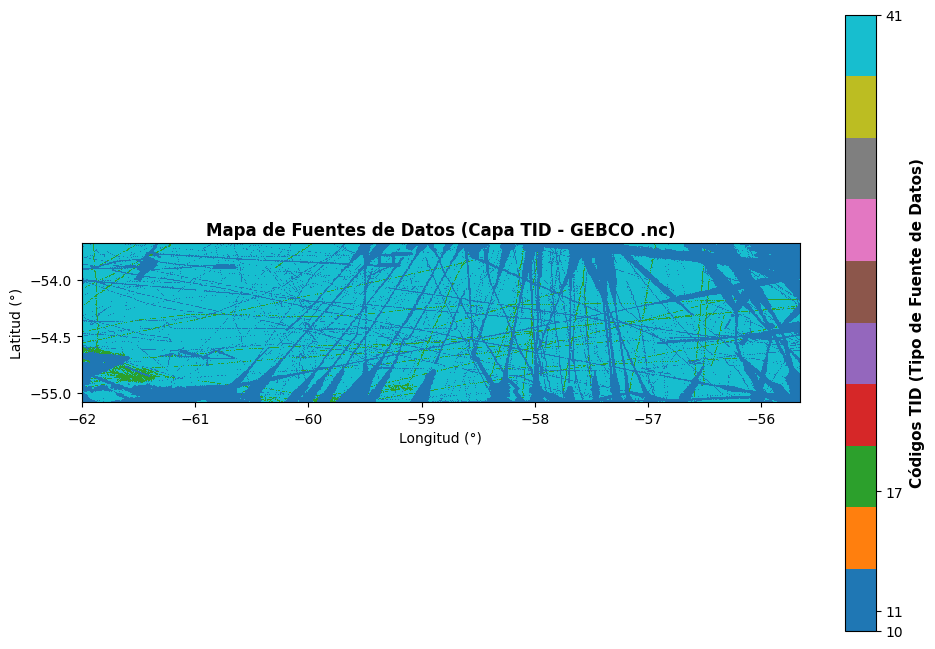

In [8]:
# Instalar dependencias necesarias si aún no las tienes
!pip install -q netCDF4 xarray matplotlib numpy cmocean

import xarray as xr
import matplotlib.pyplot as plt
import numpy as np

# --- 1. CARGAR EL ARCHIVO NETCDF DE GEBCO (.nc) ---

# Abrir el dataset
ds = xr.open_dataset(archivo_tid)
print("Variables disponibles en tu NetCDF:", list(ds.data_vars))

# --- 2. EXTRAER LAS VARIABLES DE ELEVACIÓN Y TID ---
# GEBCO suele usar 'elevation' o 'z' para la batimetría, y 'tid' para el identificador de tipo.
# Ajusta los nombres de las variables si tu archivo usa otros (ej. ds['tid'])
var_tid = 'tid' if 'tid' in ds else [v for v in ds.data_vars if 'tid' in v.lower()][0]

lons = ds['lon'].values
lats = ds['lat'].values
tid_grid = ds[var_tid].values

print(f"Variable TID seleccionada: {var_tid}")
print(f"Dimensiones de la matriz TID: {tid_grid.shape}")

# Identificar los códigos TID únicos presentes en tu zona de estudio
valores_unicos = np.unique(tid_grid[~np.isnan(tid_grid)])
print("Códigos TID encontrados en esta zona:", valores_unicos)

# --- 3. VISUALIZAR EL TID COMO MAPA CATEGÓRICO ---
fig, ax = plt.subplots(figsize=(10, 8))

# Definir los límites espaciales (extent) para el mapa
extent = [lons.min(), lons.max(), lats.min(), lats.max()]

# Usar 'imshow' con 'interpolation="nearest"' para evitar que los códigos enteros se mezclen
im = ax.imshow(
    tid_grid,
    extent=extent,
    origin='lower', # Usar 'lower' o 'upper' según cómo oriente las latitudes tu .nc
    cmap='tab10',
    interpolation='nearest'
)

# --- 4. CONFIGURAR BARRA DE COLORES DISCRETA ---
cbar = plt.colorbar(im, ax=ax, ticks=valores_unicos, shrink=0.8)
cbar.set_label('Códigos TID (Tipo de Fuente de Datos)', fontsize=11, fontweight='bold')

# Títulos y etiquetas
ax.set_title('Mapa de Fuentes de Datos (Capa TID - GEBCO .nc)', fontsize=12, fontweight='bold')
ax.set_xlabel('Longitud (°)', fontsize=10)
ax.set_ylabel('Latitud (°)', fontsize=10)

plt.tight_layout()
plt.show()